---
title: "Gebäudesektormodell Österreich 2040"
execute:
  echo: true
format:
  html:
    code-fold: true
jupyter: python3
---

# Gebäudesektormodell: Daten, Rechnung und Grenzen {#sec-gebaeudesektormodell}

## 1. Quellen und Szenarioparameter
PEExcel liefert simulierte Kennwerte; nationale Basisflächen bleiben im Hintergrundbericht.
Die Variantenflächen entstehen aus den unten sichtbaren Regeln. Die vorläufige Verteilung
ist keine statistische Erhebung. Heute hat weiterhin kein bestätigtes Bezugsjahr.
Strom und PE-Import/Export beschreiben den Betrieb; virtuelle Kontextwerte stehen separat.


In [1]:
from pathlib import Path
import sys, json, copy, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'_quarto.yml').exists())
BASE=ROOT/'Berechnungen/gebaeudesektormodell'
sys.path.insert(0,str(BASE))
from utils import read_source, sha256, markdown_table
OUT=BASE/'outputs'; OUT.mkdir(exist_ok=True)
GEN=ROOT/'Kapitel/_generated'; GEN.mkdir(exist_ok=True)
SOURCE=BASE/'data/Building-Sector_Pool_1.xlsx'
INPUT=BASE/'daten_gebauedesektor.xlsx'
# Parquet unabhängig vom persönlichen Checkout über Umgebungsvariable wählbar.
PARQUET=Path(os.environ.get('PEXL_TYPOLOGY_PARQUET', str(ROOT.parent.parent/'peexcel/data/building_typologies/building_sector_v2/scenarios.parquet')))
from variants import catalog, add_pv0, allocate, collapse, DIMENSIONS
inputs=pd.read_excel(INPUT,sheet_name=None)
bases=inputs['Typen'].copy()
applications=inputs['Anwendungen'].copy()
params=inputs['Parameter'].set_index('Parameter')['Wert'].to_dict()
r=float(params['ngf_bgf']); assert 0<r<=1
plt.rcParams.update({'figure.dpi':120,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_columns',12)
provenance={'source_sha256':sha256(PARQUET),'input_sha256':sha256(INPUT),
 'gfz_sha256':sha256(ROOT/'Berechnungen/gfz_at/outputs/recalculated/gfz_distribution_by_province_use_storeys.csv')}
display(pd.DataFrame(list(provenance.items()),columns=['Datei','SHA256']))
# Alle folgenden Restanteile sind veränderbare TESTANNAHMEN, keine Bestandsstatistik.
PEQ_TARGET = 0.20
PEQ_HULLS = ['Neu_20cm','Neu_30cm']
PEQ_HEATING = ['WP_Sole','WP_Wasser','WP_Luft','WP_Sole_fc','FW_erneu','Bio']
WEATHER = {'Wien':0.5, 'Innsbruck':0.5}
MASS = {'Leicht':1/3, 'mittel':1/3, 'schwer':1/3}
REST_2040 = {
 'Bestand': {('PV0','noFlex'):.40, ('PV30','noFlex'):.40, ('PV30','Flex'):.20},
 'Neubau': {('PV30','noFlex'):.40, ('PV30','Flex'):.40, ('PV70','Flex'):.20},
 'Sanierung': {('PV0','noFlex'):.20, ('PV30','noFlex'):.40, ('PV30','Flex'):.40}}
REST_TODAY = {s:{('PV0','noFlex'):.80, ('PV30','noFlex'):.20} for s in REST_2040}
rule_rows=[{'Stand':year,'Status':status,'PV':pv,'Flex':flex,'Anteil':v}
 for year,rules in [('heute',REST_TODAY),('2040',REST_2040)]
 for status,mix in rules.items() for (pv,flex),v in mix.items()]
display(pd.DataFrame(rule_rows))


,Datei,SHA256
0,source_sha256,29725fcc879b0ea3d1000d6ce73b189ab303c595765bb8...
1,input_sha256,cd09efbfbea7bc7e8cfd82b07146f72c6f3712d3a38162...
2,gfz_sha256,b17c1f98b6104a5b8ed6da4fe436ebff14d2f7708cc204...


,Stand,Status,PV,Flex,Anteil
0,heute,Bestand,PV0,noFlex,0.8
1,heute,Bestand,PV30,noFlex,0.2
2,heute,Neubau,PV0,noFlex,0.8
3,heute,Neubau,PV30,noFlex,0.2
4,heute,Sanierung,PV0,noFlex,0.8
5,heute,Sanierung,PV30,noFlex,0.2
6,2040,Bestand,PV0,noFlex,0.4
7,2040,Bestand,PV30,noFlex,0.4
8,2040,Bestand,PV30,Flex,0.2
9,2040,Neubau,PV30,noFlex,0.4


## 2. Typenkatalog und regelbasierte Flächenverteilung {#sec-gebaeude-datenpruefung}
Der vorhandene Export hat sieben Dimensionen. Originalidentitäten bleiben erhalten;
Zuordnungen erfolgen über explizite Merkmale. Neue Dimensionen benötigen eine bewusste Zuordnung.

Pro Basisgruppe gilt: **Variantenfläche = Basisfläche × Statusanteil × PEQ-/Restanteil × Variantenanteil × Wettergewicht × Massegewicht**.
Das nationale PEQ-Ziel wird proportional innerhalb der geeigneten Fläche verteilt.
PV70/Flex allein ist kein PEQ-Nachweis. Synthetisches PV0 übernimmt den elektrischen Nutzbedarf
von PV30/noFlex ohne Speicher; PV wird null, Netzbezug deckt den Bedarf. PE-Kennwerte bleiben
mangels zeitlich aufgelöster Neubewertung offen. Echte PV0-Simulationen haben Vorrang.


In [2]:
import pyarrow.parquet as pq
available=pq.ParquetFile(PARQUET).schema_arrow.names
metrics=list(applications.columns[1:])+[c for c in bases.columns if c.startswith(('PEI_','EUI_','PV_','Grid_'))]
metrics+=['PEI_saldo_project','PEI_flex_import','PEI_virtual_demand','PEI_virtual_supply','PEI_balance','GFA_total','NFA_total']
missing=set(metrics)-set(available)
assert not missing, f'Kennwerte fehlen: {missing}'
typology=catalog(PARQUET,metrics)
original_count=len(typology)
typology=add_pv0(typology)
np.testing.assert_allclose(typology.NFA_total/typology.GFA_total,r)
base_parts=bases.Archetype.str.split('|',expand=True)
bases['Basisarchetyp']=base_parts.iloc[:,:3].agg('|'.join,axis=1)
eligible=base_parts[1].isin(PEQ_HULLS)&base_parts[2].isin(PEQ_HEATING)
allocation2040=allocate(typology,bases,'Nationale BGF 2040',REST_2040,WEATHER,MASS,eligible,PEQ_TARGET)
# Heutige Statusstruktur ist nicht bekannt: keine Übernahme der 2040-Statusanteile.
today_bases=bases.copy(); today_bases[['Bestand','Neubau','Sanierung']]=[1.,0.,0.]
allocation_today=allocate(typology,today_bases,'Nationale BGF heute',REST_TODAY,WEATHER,MASS,eligible,0.)
future=collapse(allocation2040).set_index('Archetype')
today=collapse(allocation_today).set_index('Archetype')
data=typology.set_index('Archetype').copy()
data['Nationale BGF 2040']=future.BGF.reindex(data.index,fill_value=0)
data['Nationale BGF heute']=today.BGF.reindex(data.index,fill_value=0)
for col in ['Bestand','Neubau','Sanierung','PEQ_Anteil_2040']:
 data[col]=future[col].reindex(data.index,fill_value=0)
data['Energetischer Standard']=np.where(data.PEQ_Anteil_2040.gt(0),'PEQ-Szenarioanteil','')
data['BGF_2020_m2']=np.nan
for year in ['heute','2040']:
 data['Flächenanteil '+year]=data['Nationale BGF '+year]/data['Nationale BGF '+year].sum()
data=data.reset_index()
np.testing.assert_allclose((data.PEQ_Anteil_2040*data['Nationale BGF 2040']).sum()/data['Nationale BGF 2040'].sum(),PEQ_TARGET)
display(pd.DataFrame([{'Dimension':c,'Klassen':data[c].nunique(),'Werte':', '.join(sorted(data[c].unique()))} for c in DIMENSIONS]))
# Vollständiges Rechenbeispiel für eine positiv gewichtete Basisgruppe.
example=allocation2040.Basisarchetyp.iloc[0]
display(allocation2040.loc[allocation2040.Basisarchetyp.eq(example),['Basisarchetyp','Status','PEQ',*DIMENSIONS[3:],'BGF']])
data[['Archetype',*DIMENSIONS,'Herkunft','Bestand','Neubau','Sanierung','PEQ_Anteil_2040','Nationale BGF heute','Nationale BGF 2040']].to_csv(OUT/'typologien.csv',index=False)
pd.DataFrame(rule_rows).to_csv(OUT/'variantenregeln.csv',index=False)
provenance['rules']={'peq_target':PEQ_TARGET,'hulls':PEQ_HULLS,'heating':PEQ_HEATING,'weather':WEATHER,'mass':MASS,'variant_shares':rule_rows}


,Dimension,Klassen,Werte
0,Geometrie,10,"EFH_1G, EFH_2G, GWB_5G, GWB_7G, MFH_2G, MFH_4G..."
1,Huelle,9,"1919-44, 1945-59, 1960-79, 1980-89, 1990-99, N..."
2,Heizung,10,"Bio, Elektro, Erdgas, FW_Wien, FW_erneu, Oel, ..."
3,PV_Klasse,4,"PV0, PV30, PV70, PV90"
4,Flexibilitaet,2,"Flex, noFlex"
5,Wetter,2,"Innsbruck, Wien"
6,Masse,3,"Leicht, mittel, schwer"


,Basisarchetyp,Status,PEQ,PV_Klasse,Flexibilitaet,Wetter,Masse,BGF
0,EFH_1G|vor1919|WP_Wasser,Bestand,False,PV0,noFlex,Wien,Leicht,2399.605125
1,EFH_1G|vor1919|WP_Wasser,Bestand,False,PV0,noFlex,Wien,mittel,2399.605125
2,EFH_1G|vor1919|WP_Wasser,Bestand,False,PV0,noFlex,Wien,schwer,2399.605125
3,EFH_1G|vor1919|WP_Wasser,Bestand,False,PV0,noFlex,Innsbruck,Leicht,2399.605125
4,EFH_1G|vor1919|WP_Wasser,Bestand,False,PV0,noFlex,Innsbruck,mittel,2399.605125
5,EFH_1G|vor1919|WP_Wasser,Bestand,False,PV0,noFlex,Innsbruck,schwer,2399.605125
6,EFH_1G|vor1919|WP_Wasser,Bestand,False,PV30,noFlex,Wien,Leicht,2399.605125
7,EFH_1G|vor1919|WP_Wasser,Bestand,False,PV30,noFlex,Wien,mittel,2399.605125
8,EFH_1G|vor1919|WP_Wasser,Bestand,False,PV30,noFlex,Wien,schwer,2399.605125
9,EFH_1G|vor1919|WP_Wasser,Bestand,False,PV30,noFlex,Innsbruck,Leicht,2399.605125


## 3. Flächenbilanz {#sec-gebaeude-flaechen}
Die Basisflächen bleiben je Geometrie/Hülle/Versorgung erhalten. NGF = BGF × 0,8;
dies entspricht auch NFA_total/GFA_total im aktuellen Pool. Statusanteile sind flächengewichtet.
2020 bleibt offen. Nullflächen sind explizit ausgeschlossen, fehlende Angaben bleiben unbekannt.


,Stand,BGF [Mio. m²],NGF [Mio. m²],positiv,Null,fehlend
0,heute,1112.340697,889.872558,7020,30780,0
1,2040,1126.578658,901.262927,11502,26298,0
2,2020,NaN,NaN,0,0,37800


heute max. Abweichung der gelieferten Anteilsfelder: 0.0
2040 max. Abweichung der gelieferten Anteilsfelder: 0.0


,Zustand,BGF 2040 [Mio. m²]
0,Bestand,779.528361
1,Neubau,320.354121
2,Sanierung,26.696177


,Nationale BGF heute,Nationale BGF 2040
Geometrie,,
EFH_1G,129.675450,131.046774
EFH_2G,186.891308,189.492325
GWB_5G,39.451509,39.940921
GWB_7G,81.032363,82.107513
MFH_2G,0.000000,0.000000
MFH_4G,65.007145,65.864754
NiWo_1G,90.878367,92.026259
NiWo_2G,138.179441,139.840450
NiWo_3G,194.333808,196.767338


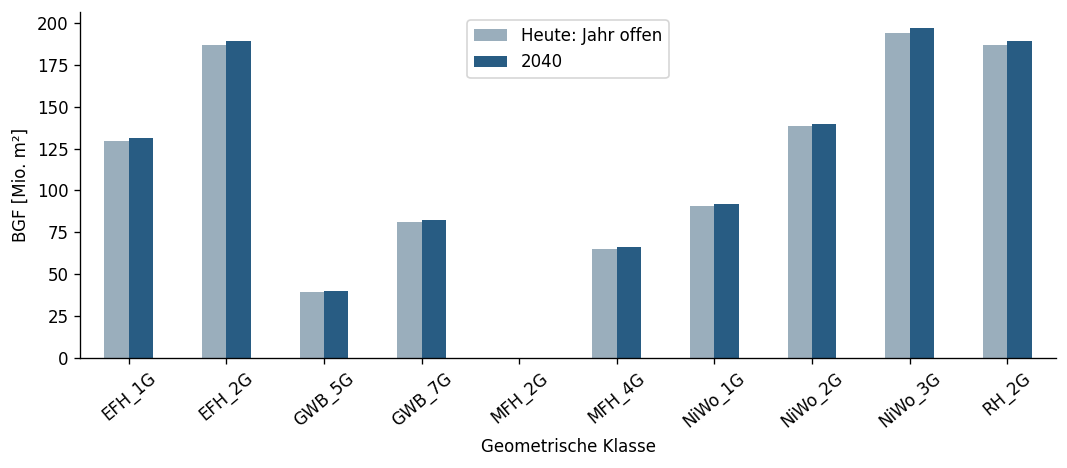

In [3]:
area_cols={'heute':'Nationale BGF heute','2040':'Nationale BGF 2040','2020':'BGF_2020_m2'}
for c in area_cols.values():
    assert data[c].dropna().ge(0).all()
areas=[]
for year,c in area_cols.items():
    areas.append({'Stand':year,'BGF [Mio. m²]':data[c].sum(min_count=1)/1e6,
                  'NGF [Mio. m²]':r*data[c].sum(min_count=1)/1e6,
                  'positiv':int(data[c].gt(0).sum()),'Null':int(data[c].eq(0).sum()),'fehlend':int(data[c].isna().sum())})
area_summary=pd.DataFrame(areas);display(area_summary)
for year,share in [('heute','Flächenanteil heute'),('2040','Flächenanteil 2040')]:
    # Quellanteile prüfen; nach redaktioneller Änderung absolute Flächen maßgeblich halten.
    expected=data[area_cols[year]]/data[area_cols[year]].sum(min_count=1)
    print(year,'max. Abweichung der gelieferten Anteilsfelder:',abs(data[share]-expected).max())
statussum=data[['Bestand','Neubau','Sanierung']].sum(axis=1,min_count=3)
assert np.allclose(statussum[data['Nationale BGF 2040'].gt(0)],1)
status=pd.DataFrame([{'Zustand':c,'BGF 2040 [Mio. m²]':(data[c]*data['Nationale BGF 2040']).sum(min_count=1)/1e6} for c in ['Bestand','Neubau','Sanierung']])
display(status)
geometry_area=data.groupby('Geometrie')[['Nationale BGF heute','Nationale BGF 2040']].sum(min_count=1)/1e6
display(geometry_area)
fig,ax=plt.subplots(figsize=(9,4));geometry_area.plot.bar(ax=ax,color=['#9aaebc','#285c83'])
ax.set(ylabel='BGF [Mio. m²]',xlabel='Geometrische Klasse');ax.tick_params(axis='x',rotation=40)
ax.legend(['Heute: Jahr offen','2040']);fig.tight_layout();fig.savefig(OUT/'flaechen.png',dpi=180);plt.show()
area_summary.to_csv(OUT/'flaechenaudit.csv',index=False)

## 4. Physische Strombilanz {#sec-gebaeude-strom}
Bruttobedarf folgt EUI_el_total ohne EUIev_el; Mobilität wird erst beim sektoralen Vergleich angesetzt.
PV_total umfasst direkten und flexiblen Verbrauch sowie Einspeisung. Die Flussprüfung
berücksichtigt deshalb PV_total_flex und VRGrid_to_building. Keine virtuellen Kontextwerte
werden als Erzeugung addiert. Die Anwendungssummen schließen direktes elektrisches Warmwasser ein.


,Stand,Größe,kWh/(m² NGF a),GWh/a,PJ/a,fehlende BGF [m²],Flächen offen
8,2040,Strombedarf,46.096868,41545.398098,149.563433,0.0,False
9,2040,PV_Erzeugung,41.390673,37303.879240,134.293965,0.0,False
10,2040,Grid_to_building_min,29.255455,26366.856933,94.920685,0.0,False
11,2040,PV_total_direct,11.574344,10431.526906,37.553497,0.0,False
12,2040,PV_total_flex,1.635729,1474.221784,5.307198,0.0,False
13,2040,VRGrid_to_building,3.631340,3272.792475,11.782053,0.0,False
14,2040,PV_to_Egrid,28.180601,25398.130550,91.433270,0.0,False
15,2040,Stromsaldo,-4.706195,-4241.518858,-15.269468,0.0,False


,GWh/a
Heizung,8972.641557
Warmwasser,1351.416608
Kühlung,1153.702458
Lüftung,1053.688634
Hilfs-/Allgemeinstrom,3699.032481
Beleuchtung,3726.317792
Geräte/IT,21588.598568


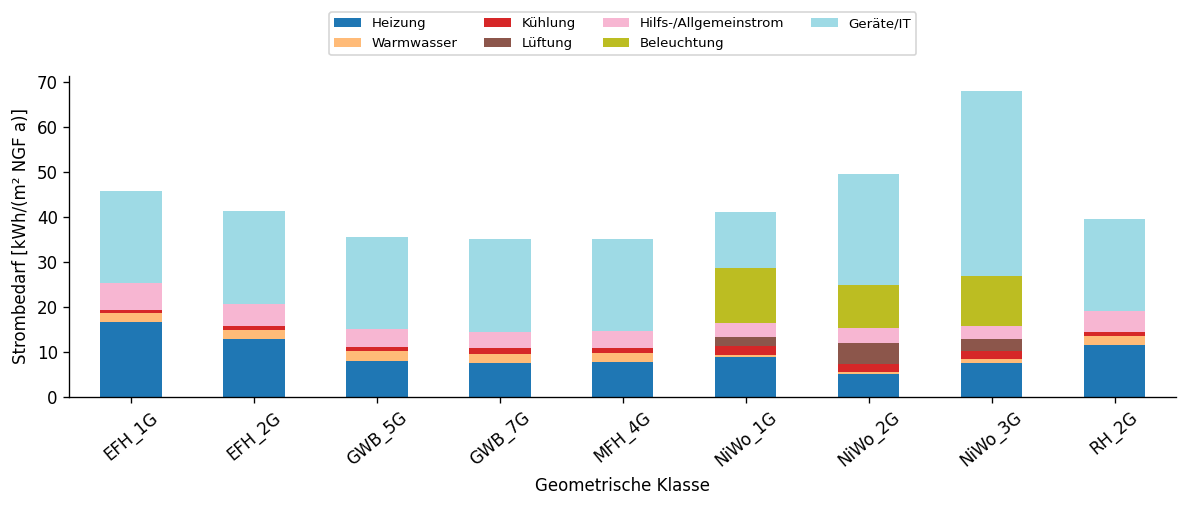

,Strombedarf,PV_Erzeugung,Stromsaldo
Geometrie,,,
EFH_1G,4799.000506,8632.071388,3833.070883
EFH_2G,6241.716297,5923.233624,-318.482673
GWB_5G,1135.072491,519.486715,-615.585775
GWB_7G,2295.948900,761.475104,-1534.473796
MFH_2G,0.000000,0.000000,0.000000
MFH_4G,1846.795025,1055.251517,-791.543508
NiWo_1G,3018.093515,5824.012452,2805.918937
NiWo_2G,5528.276497,4478.549148,-1049.727349
NiWo_3G,10691.926484,4186.565667,-6505.360817


In [4]:
data['Strombedarf']=data.EUI_el_total-data.EUIev_el
data['PV_Erzeugung']=data.PV_total
data['Stromsaldo']=data.PV_Erzeugung-data.Strombedarf
np.testing.assert_allclose(data.PV_total,data.PV_total_direct+data.PV_total_flex+data.PV_to_Egrid,atol=1e-7)
np.testing.assert_allclose(data.Strombedarf,data.Grid_to_building_min+data.VRGrid_to_building+data.PV_total_direct+data.PV_total_flex,atol=1e-7)
apps=pd.DataFrame({'Heizung':data.EUIh_el-data.EUIh_el_aux,
 'Warmwasser':data.EUIdhw_el+data.EUIdhwdirect_el-data.Edhw_aux_el,'Kühlung':data.EUIc_el-data.EUIc_el_aux,
 'Lüftung':data.EUIv_el,'Hilfs-/Allgemeinstrom':data.EUI_auxiliary+data.EUIh_el_aux+data.EUIc_el_aux+data.Edhw_aux_el,
 'Beleuchtung':data.EUI_lighting,'Geräte/IT':data.EUI_plugloads})
assert (apps.min()>=-1e-7).all()
np.testing.assert_allclose(apps.sum(axis=1,min_count=7),data.Strombedarf,atol=1e-7)
# Vollsummen bleiben bei fehlender positiver Fläche/Kennwert offen.
def aggregate(values, area):
    missing_area=area.isna().any()
    active=area.gt(0)
    covered=active & values.notna()
    known=(values[covered]*area[covered]*r).sum(min_count=1)
    missing=area[active & values.isna()].sum()
    return dict(kWh=known if not missing_area and missing==0 else np.nan,
                bekannte_kWh=known,fehlende_BGF_m2=missing,Flächen_offen=missing_area)
energy_records=[]
for year,c in area_cols.items():
    for metric in ['Strombedarf','PV_Erzeugung','Grid_to_building_min','PV_total_direct','PV_total_flex','VRGrid_to_building','PV_to_Egrid','Stromsaldo']:
        a=aggregate(data[metric],data[c]);energy_records.append({'Stand':year,'Größe':metric,
            'kWh/(m² NGF a)':a['kWh']/(data[c].sum(min_count=1)*r),
            'GWh/a':a['kWh']/1e6,'PJ/a':a['kWh']*3.6e-9,'fehlende BGF [m²]':a['fehlende_BGF_m2'],'Flächen offen':a['Flächen_offen']})
energy=pd.DataFrame(energy_records);display(energy[energy.Stand.eq('2040')])
weighted_apps=apps.mul(data['Nationale BGF 2040']*r,axis=0)
application_total=weighted_apps.sum(min_count=1)/1e6
display(application_total.rename('GWh/a').to_frame())
by_geometry=weighted_apps.groupby(data.Geometrie).sum(min_count=1).div((data['Nationale BGF 2040']*r).groupby(data.Geometrie).sum(),axis=0)
fig,ax=plt.subplots(figsize=(10,4.5));by_geometry.dropna(how='all').plot.bar(stacked=True,ax=ax,colormap='tab20')
ax.set(ylabel='Strombedarf [kWh/(m² NGF a)]',xlabel='Geometrische Klasse');ax.tick_params(axis='x',rotation=40)
ax.legend(loc='upper center',bbox_to_anchor=(.5,1.22),ncol=4,fontsize=8);fig.tight_layout();fig.savefig(OUT/'strom_anwendungen.png',dpi=180);plt.show()
geom_energy=data[['Strombedarf','PV_Erzeugung','Stromsaldo']].mul(data['Nationale BGF 2040']*r,axis=0).groupby(data.Geometrie).sum(min_count=1)/1e6
display(geom_energy)
energy.to_csv(OUT/'strombilanz.csv',index=False);by_geometry.to_csv(OUT/'strom_anwendungen_spezifisch.csv');geom_energy.to_csv(OUT/'strombilanz_geometrie.csv')

## 5. Endenergiebilanz nach Energieträgern und Anwendungen {#sec-gebaeude-endenergie}

Die elektrische Heizung ist nicht die gesamte Wärmeversorgung. Die Quelle enthält Fernwärme, Erdgas, Biomasse und „other“. **Öl wird aus `EUI_other` nur für Schlüssel mit Heizsystem `Oel` herausgelöst**. Ein anderer „other“-Betrag bleibt sonstige thermische Endenergie. Die Anwendungsaufteilung stammt aus den zugehörigen `EUIh_*`, `EUIdhw_*` und `EUIc_other`-Spalten, nicht aus angenommenen Wirkungsgraden.

$$E_{i,y}=\sum_k A_{NGF,k,y}\,e_{i,k},\qquad E_{End,y}=E_{el,y}+\sum_{i\ne el}E_{i,y}.$$

Der Bruttostrombedarf enthält lokal genutzten PV-Strom. Die alternativ ausgewiesene externe Lieferung enthält nur Netzbezug plus thermische Energieträger. Umweltwärme ist in diesen gelieferten Trägerkennwerten nicht als zusätzliche Endenergielieferung enthalten; diese Abgrenzung ist beim Vergleich mit nationalen Statistiken zu beachten.

,Träger,Anwendung,GWh/a
0,Fernwärme,Heizung,31096.147494
1,Fernwärme,Warmwasser,2919.601453
2,Gas,Heizung,24473.782294
3,Gas,Warmwasser,1539.236595
4,Biomasse,Heizung,22121.710487
5,Biomasse,Warmwasser,1398.711472
6,Sonstige inkl. Öl,Heizung,19201.132987
7,Sonstige inkl. Öl,Warmwasser,911.609076
8,Sonstige inkl. Öl,Kühlung,0.000000


,Stand,Träger,kWh/(m² NGF a),GWh/a,PJ/a
6,2040,Strom (Bruttobedarf),46.096868,41545.398098,149.563433
7,2040,Fernwärme,37.742315,34015.748948,122.456696
8,2040,Gas,28.862852,26013.018889,93.646868
9,2040,Biomasse,26.097181,23520.421959,84.673519
10,2040,Öl,22.316176,20112.742063,72.405871
11,2040,Sonstige thermisch,0.000000,0.000000,0.000000


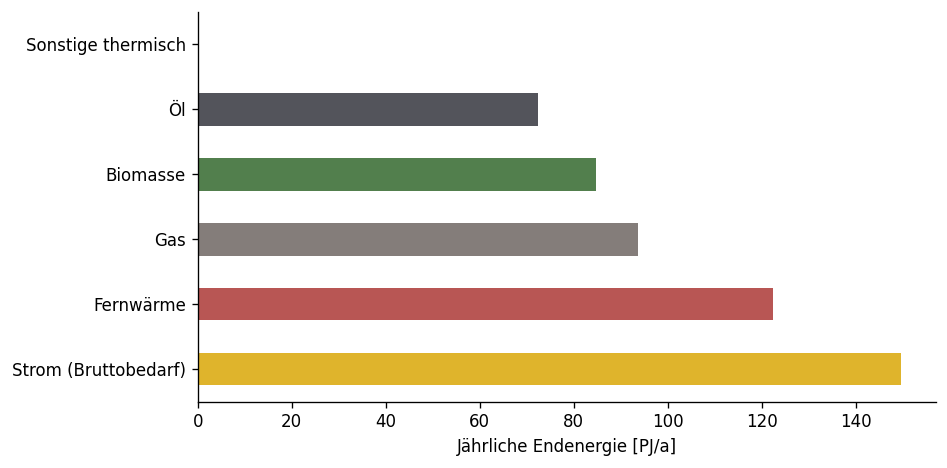

In [5]:
carriers=pd.DataFrame({'Strom (Bruttobedarf)':data.Strombedarf,'Fernwärme':data.EUI_district_heating,
 'Gas':data.EUI_natural_gas,'Biomasse':data.EUI_biomass,
 'Öl':data.EUI_other.where(data.Heizung.eq('Oel'),0),
 'Sonstige thermisch':data.EUI_other.where(~data.Heizung.eq('Oel'),0)})
thermal_apps=[]
for carrier,suffix in [('Fernwärme','district_heating'),('Gas','natural_gas'),('Biomasse','biomass'),('Sonstige inkl. Öl','other')]:
    comps={'Heizung':data['EUIh_'+suffix],'Warmwasser':data['EUIdhw_'+suffix]}
    if suffix=='other': comps['Kühlung']=data.EUIc_other
    np.testing.assert_allclose(sum(comps.values()),data['EUI_'+suffix],atol=1e-7)
    for app,series in comps.items():
        thermal_apps.append({'Träger':carrier,'Anwendung':app,'GWh/a':aggregate(series,data['Nationale BGF 2040'])['kWh']/1e6})
display(pd.DataFrame(thermal_apps))
ee=[]
for year,c in area_cols.items():
    for carrier in carriers:
        a=aggregate(carriers[carrier],data[c]);ee.append({'Stand':year,'Träger':carrier,
            'kWh/(m² NGF a)':a['kWh']/(data[c].sum(min_count=1)*r),'GWh/a':a['kWh']/1e6,'PJ/a':a['kWh']*3.6e-9})
endenergy=pd.DataFrame(ee);display(endenergy[endenergy.Stand.eq('2040')])
endenergy.to_csv(OUT/'endenergiebilanz.csv',index=False)
pd.DataFrame(thermal_apps).to_csv(OUT/'thermische_anwendungen_2040.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4));endenergy[endenergy.Stand.eq('2040')].set_index('Träger')['PJ/a'].plot.barh(ax=ax,color=['#dfb42c','#b85654','#847d7a','#527f4d','#53545b','#9b8c70'])
ax.set(xlabel='Jährliche Endenergie [PJ/a]',ylabel='');fig.tight_layout();fig.savefig(OUT/'endenergie.png',dpi=180);plt.show()

## 6. PE-Bewertung realer Import-/Exportflüsse {#sec-gebaeude-pe}
PEI_saldo_project = PEI_export − PEI_import. Netzbezug und flexible Bezüge sind Komponenten,
thermische Energieträger bleiben enthalten. Die Größen sind keine virtuellen Kontextbilanzen.
Für synthetisches PV0 bleiben PE-Kennwerte offen; daher wird keine vollständige nationale
PE-Summe behauptet. Die physische Stromrechnung ist davon unabhängig vollständig.


In [6]:
data['PE_Saldo']=data.PEI_saldo_project
np.testing.assert_allclose(data.PEI_saldo_project,data.PEI_export-data.PEI_import,atol=1e-7,equal_nan=True)
pe_records=[]
for year,c in area_cols.items():
    for metric in ['PEI_grid_import','PEI_flex_import','PEI_import','PEI_export','PE_Saldo']:
        a=aggregate(data[metric],data[c]);pe_records.append({'Stand':year,'Größe':metric,'GWh_PE/a':a['kWh']/1e6,'PJ_PE/a':a['kWh']*3.6e-9,'bekannter Teil [PJ PE/a]':a['bekannte_kWh']*3.6e-9,'fehlende BGF [m²]':a['fehlende_BGF_m2']})
primary=pd.DataFrame(pe_records);display(primary[primary.Stand.eq('2040')])
implicit=[]
for carrier,ee_col,pe_col in [('Netzstrom','Grid_to_building_min','PEI_grid_import'),('PV-Export','PV_to_Egrid','PEI_export'),
 ('Fernwärme','EUI_district_heating','PEI_district_heating'),('Gas','EUI_natural_gas','PEI_natural_gas'),
 ('Biomasse','EUI_biomass','PEI_biomass'),('Sonstige inkl. Öl','EUI_other','PEI_other')]:
    f=data[pe_col].div(data[ee_col].where(data[ee_col].ne(0)))
    implicit.append(pd.DataFrame({'Archetype':data.Archetype,'Träger':carrier,'f_PE_effektiv':f,'Bezugsjahr':params['jahr_pe_bewertung']}))
implicit=pd.concat(implicit,ignore_index=True);display(implicit.groupby('Träger').f_PE_effektiv.agg(['min','max']))
primary.to_csv(OUT/'primaerenergiebilanz.csv',index=False);implicit.to_csv(OUT/'pe_faktoren_effektiv.csv',index=False)

,Stand,Größe,GWh_PE/a,PJ_PE/a,bekannter Teil [PJ PE/a],fehlende BGF [m²]
5,2040,PEI_grid_import,NaN,NaN,108.757754,2.921138e+08
6,2040,PEI_flex_import,NaN,NaN,0.000000,2.921138e+08
7,2040,PEI_import,NaN,NaN,323.694311,2.921138e+08
8,2040,PEI_export,NaN,NaN,145.376462,2.921138e+08
9,2040,PE_Saldo,NaN,NaN,-178.317849,2.921138e+08


,min,max
Träger,,
Biomasse,1.130000,1.130000
Fernwärme,0.330000,1.706992
Gas,1.100000,1.100000
Netzstrom,1.830161,2.074044
PV-Export,1.404420,1.645950
Sonstige inkl. Öl,1.200000,1.200000


## 7. GFZ-Zuordnung, Flächengewichtung und Dichte-Erwartungswert {#sec-gebaeude-gfz}

Die Zuordnung aus `zuordnung_gfz` wird auf die Kategorien der vorhandenen GFZ-Hochrechnung 2021 übersetzt. Die Quellgruppen mit einer bzw. zwei Wohnungen haben identische Zuordnungen und werden **einmal** auf die zusammengefasste GFZ-Gruppe „Ein- und Zweifamilienhäuser“ angewendet. Die 50/50-Aufteilung zwischen EFH_2G und RH_2G wird übernommen. Die vom Auftraggeber am 23.10.2026 bestätigte Regel lautet: **Eine einzige Zielklasse erhält 100 %; die zweite Zielspalte dient nur einer Aufteilung.** Die aktualisierte Excel enthält diese 100-%-Werte nun explizit. Es sind keine fehlenden Quellanteile mehr zu ergänzen. Die Regel bleibt für weitere Einzelzuordnungen implementiert und wird im Audit protokolliert. MFH_2G hat keine Zuordnung und keine positive Fläche; sein Erwartungswert bleibt leer. Es wird kein Ersatz aus anderen Gebäudetypen erfunden.

Aus GFZ-Referenzfläche $R_{u,g,j}$ und Zuordnungsanteil $z_{u,g,k}$ entsteht
$$R_{k,j}=\sum_{u,g}z_{u,g,k}R_{u,g,j},\qquad s_{j|k}=R_{k,j}/\sum_j R_{k,j}.$$
Diese **bedingte Verteilung** wird auf die unabhängig gelieferte Typenfläche übertragen: $A_{k,j}^{2040}=A_k^{2040}s_{j|k}$. Die Referenzfläche wird nicht als zusätzliche nationale Fläche addiert. Die Annahme ist, dass Hüll- und Technikvarianten derselben Geometrie die gleiche Dichteverteilung besitzen; eine räumliche Änderung bis 2040 ist damit noch nicht modelliert. Die vorhandene freigegebene GFZ-Ersatzregel (1,696 % Referenz-BGF) bleibt unverändert.

Als historische **elektrische** Referenz wird die Tabellenparametrisierung der PED-Typen aus Schneider et al. (2023), Gl. 7/Tabelle 5, verwendet [@schneider2023context]:
$$c_D^{el}(d)=-\min\left(\frac{30{,}4}{d+0{,}15}-26{,}4;62\right)\quad[kWh/(m^2\,BGF\,a)].$$
Die Originaltabelle enthält widersprüchliche EE-/PE-Einheitenbeschriftungen (insbesondere bei der Begrenzung). Hier wird die elektrische Tabellenlesart als **Referenzansatz** dokumentiert; daraus entsteht keine neu freigegebene Anforderung. Die bereits PE-gewichteten Kontextwerte der Einzelsimulation werden nicht als EE ausgegeben und nicht zur GFZ-Hochrechnung benutzt. Positive $c_D$ sind virtuelle Gutschriften, negative zusätzliche Anforderungen.

$$\mathbb E_k[GFZ]=\sum_j s_{j|k}d_j,\qquad\mathbb E_k[c_D]=\sum_j s_{j|k}c_D(d_j).$$
Wegen der Nichtlinearität gilt im Allgemeinen $\mathbb E[c_D(d)]\ne c_D(\mathbb E[d])$. NGF-spezifische Kontextwerte ergeben sich durch Division durch $r$, noch **ohne PE-Umrechnung**. Die Verteilung des Kontextwerts wird für jeden GFZ-Bin exportiert; die Typenerwartung beschreibt den Kalibrierungsansatz, nicht einer automatischen Gutschrift für alle Typen.

### Was bedeutet der Erwartungswert?

| Symbol | Bedeutung | Einheit |
|---|---|---|
| $k$ | Energetischer Gebäudetyp; die GFZ-Verteilung folgt seiner Geometrie | – |
| $u,g$ | Statistische Nutzung und Geschoßklasse | – |
| $j$ | GFZ-Bin im Referenzraster | – |
| $d_j$ | GFZ des Bins | m² BGF / m² Grundstück |
| $R_{u,g,j}$ | Referenz-BGF der Nutzung/Geschoßklasse im Bin | m² BGF |
| $z_{u,g,k}$ | Zuordnungsanteil aus `zuordnung_gfz` | 0–1 |
| $s_{j\mid k}$ | Anteil des Bins an der BGF von Typ $k$; Summe über $j$ = 1 | 0–1 |
| $c_D(d_j)$ | Dichtewert im Bin; positiv = Gutschrift, negativ = Zusatzanforderung | kWh EE/(m² BGF·a) |
| $\mathbb E_k[c_D]$ | Mit $s_{j\mid k}$ gewichteter mittlerer Dichtewert des Typs | kWh EE/(m² BGF·a) |
| $A_{BGF,k}$ | Nationale BGF des Typs 2040 | m² BGF |
| $C_{D,k}$ | Virtueller jährlicher Beitrag des Typs: $A_{BGF,k}\mathbb E_k[c_D]$ | kWh EE-Äquivalent/a |

**Beispiel EFH_1G:** Der mittlere Kontextwert beträgt −41,63 kWh EE/(m² BGF·a).
Bei 1 Mio. m² BGF entspricht dies −0,150 PJ-Äquivalent/a. Das negative Vorzeichen
erhöht die Anforderung an diese Geometrie; es beschreibt keine zusätzliche Stromlast.

### Anwendung im Vergleichsfall

Die physische Typenbilanz lautet $b_k=r(e_{PV,k}-e_{el,k})$ je m² BGF.
Der Vergleichsfall ergänzt sie zu $b_{k,D}=b_k+\mathbb E_k[c_D]$.
Damit gilt national:

$$B_D=B_{phys}+C_D,\qquad C_D=\sum_k A_{BGF,k}\mathbb E_k[c_D].$$

Die anschließende Grafik zeigt Bedarf, PV und Kontextwert getrennt für **alle Typen**.
Geometrieauswahl und Achsenregler halten die Darstellung lesbar. Der Tooltip nennt
die nationale BGF; Typen mit Nullfläche tragen national nichts bei. Für MFH_2G bleibt
der nicht zugeordnete Kontextwert leer.

Für den nationalen Vergleich wird die historische Formel auf alle positiv gewichteten
Flächen angewandt. Das ist eine explizite Bewertungsvariante, keine Festlegung, dass
jede Fläche PEQ-berechtigt ist. Eine eingeschränkte Anwendung benötigt typenspezifische
PEQ-Anteile. Die physischen Kennwerte und die PE-Bilanz werden durch diese Variante
nicht verändert.


Nach bestätigter Einzelzielregel ergänzte leere Anteile: 0 Quellzeilen
Davon betroffene Referenz-BGF [%]: 0.0


,GFZ_Mittel,c_D_EE_BGF,Referenz_BGF,c_D_EE_NGF,c_am_GFZ_Mittel
Geometrie,,,,,
EFH_1G,0.317942,-41.630722,1.297227e+08,-52.038402,-38.565338
EFH_2G,0.614984,-22.798103,1.724298e+08,-28.497629,-13.339407
GWB_5G,2.266322,8.965535,3.707040e+07,11.206919,13.818897
GWB_7G,4.000472,16.439657,7.518450e+07,20.549571,19.075532
MFH_4G,1.541462,1.431515,6.056382e+07,1.789394,8.427382
NiWo_1G,0.490604,-29.353340,8.710480e+07,-36.691675,-21.055233
NiWo_2G,0.874806,-13.124038,1.368895e+08,-16.405047,-3.264162
NiWo_3G,2.183130,3.923841,1.875395e+08,4.904801,13.370295
RH_2G,0.614984,-22.798103,1.724298e+08,-28.497629,-13.339407


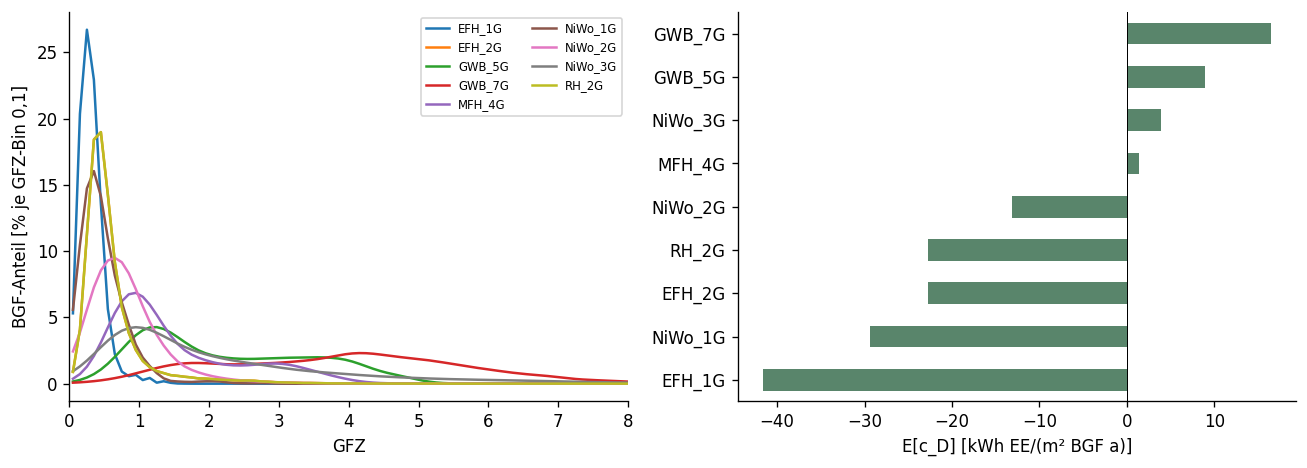

C:\Users\schneids\AppData\Roaming\Python\Python313\site-packages\IPython\core\display.py:447: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


In [7]:
mapping=inputs['GFZ_Zuordnung'].copy()
use_map={'Gebäude für Gemeinschaften':'Gemeinschaftsgebäude','Hotels und ähnliche Gebäude':'Hotels o.Ä.',
 'Bürogebäude':'Büronutzung','Groß- und Einzelhandelsgebäude':'Groß- und Einzelhandelsgebäude',
 'Gebäude des Verkehrs- und Nachrichtenwesens':'Verkehrs- und Nachrichtenwesen','Industrie- und Lagergebäude':'Industrie und Lagerung',
 'Gebäude für Kultur- und Freizeitzwecke sowie des Bildungs- und Gesundheitswesens':'Kultur, Freizeit, Bildung und Gesundheit',
 'Wohngebäude mit einer Wohnung':'Ein- und Zweifamilienhäuser','Wohngebäude mit zwei Wohnungen':'Ein- und Zweifamilienhäuser',
 'Wohngebäude mit drei und mehr Wohnungen':'Mehrfamilienhaus'}
mapping['GWR_Nutzung']=mapping.Nutzung.map(use_map); assert mapping.GWR_Nutzung.notna().all()
mapping['GK']=mapping.Geschoss.str.replace(' Geschoße','',regex=False).str.replace(' Geschoß','',regex=False).replace({'6 bis 10':'6-10','11 und mehr':'11+'})
mapping['Einzelziel_ergänzt']=mapping.Anteil1.isna() & mapping.Archetype1.notna() & mapping.Archetype2.isna()
if params['single_target_missing_share']==1:
    mapping.loc[mapping['Einzelziel_ergänzt'],'Anteil1']=1.0
mapping.to_csv(OUT/'gfz_zuordnung_audit.csv',index=False)
# Doppelte Statistiknutzungen nur zusammenführen, wenn ihre Regeln identisch sind.
for key,group in mapping.groupby(['GWR_Nutzung','GK']):
    assert len(group[['Anteil1','Archetype1','Anteil2','Archetype2']].drop_duplicates())==1,key
unique=mapping.drop_duplicates(['GWR_Nutzung','GK'])
long=[]
for _,row in unique.iterrows():
    for n in [1,2]:
        if pd.notna(row[f'Archetype{n}']):
            long.append({'GWR_Nutzung':row.GWR_Nutzung,'GK':row.GK,'Geometrie':row[f'Archetype{n}'],'Anteil':row[f'Anteil{n}']})
links=pd.DataFrame(long)
assert links.Anteil.notna().all(), 'GFZ-Anteile offen; Einzelzielregel oder Eingaben prüfen'
assert links.Anteil.between(0,1).all()
np.testing.assert_allclose(links.groupby(['GWR_Nutzung','GK']).Anteil.sum(),1)
gfz=pd.read_csv(ROOT/'Berechnungen/gfz_at/outputs/recalculated/gfz_distribution_by_province_use_storeys.csv',dtype={'GK':str})
joined=gfz.merge(links,on=['GWR_Nutzung','GK'],how='left',indicator=True)
assert joined['_merge'].eq('both').all()
joined['zugeordnete_BGF']=joined.BGF_m2*joined.Anteil
np.testing.assert_allclose(joined.zugeordnete_BGF.sum(),gfz.BGF_m2.sum(),rtol=1e-12)
bins=joined.groupby(['Geometrie','GFZ'],as_index=False).zugeordnete_BGF.sum()
bins['s']=bins.zugeordnete_BGF/bins.groupby('Geometrie').zugeordnete_BGF.transform('sum')
bins['c_D_EE_BGF']=-np.minimum(float(params['density_f_res'])/(bins.GFZ+float(params['density_dx']))-float(params['density_f_ed']),float(params['density_cutoff']))
bins['c_D_EE_NGF']=bins.c_D_EE_BGF/r
bins['gew_GFZ']=bins.GFZ*bins.s; bins['gew_c']=bins.c_D_EE_BGF*bins.s
density=bins.groupby('Geometrie').agg(GFZ_Mittel=('gew_GFZ','sum'),c_D_EE_BGF=('gew_c','sum'),Referenz_BGF=('zugeordnete_BGF','sum'))
density['c_D_EE_NGF']=density.c_D_EE_BGF/r
density['c_am_GFZ_Mittel']=-np.minimum(float(params['density_f_res'])/(density.GFZ_Mittel+float(params['density_dx']))-float(params['density_f_ed']),float(params['density_cutoff']))
data=data.merge(density[['GFZ_Mittel','c_D_EE_BGF','c_D_EE_NGF']],left_on='Geometrie',right_index=True,how='left',validate='many_to_one')
assert data.loc[data['Nationale BGF 2040'].gt(0),'GFZ_Mittel'].notna().all()
print('Nach bestätigter Einzelzielregel ergänzte leere Anteile:',int(mapping['Einzelziel_ergänzt'].sum()),'Quellzeilen')
affected=unique.loc[unique['Einzelziel_ergänzt'],['GWR_Nutzung','GK']]
affected_area=gfz.merge(affected,on=['GWR_Nutzung','GK']).BGF_m2.sum()
print('Davon betroffene Referenz-BGF [%]:',100*affected_area/gfz.BGF_m2.sum())
display(density)
matrix=data.loc[data['Nationale BGF 2040'].gt(0),['Archetype','Geometrie','Nationale BGF 2040']].merge(bins[['Geometrie','GFZ','s','c_D_EE_BGF']],on='Geometrie',validate='many_to_many')
matrix['BGF_2040_m2']=matrix['Nationale BGF 2040']*matrix.s
by_type=matrix.groupby('Archetype').BGF_2040_m2.sum()
np.testing.assert_allclose(by_type,data.set_index('Archetype').loc[by_type.index,'Nationale BGF 2040'],rtol=1e-12)
matrix[['Archetype','Geometrie','GFZ','s','BGF_2040_m2','c_D_EE_BGF']].to_csv(OUT/'typologie_gfz_2040.csv.gz',index=False,compression='gzip')
bins.to_csv(OUT/'gfz_kontext_verteilungen.csv',index=False);density.to_csv(OUT/'dichte_erwartungswerte.csv')
data[['Archetype','Geometrie','GFZ_Mittel','c_D_EE_BGF','c_D_EE_NGF','Nationale BGF 2040']].to_csv(OUT/'typologie_dichte.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,g in bins.groupby('Geometrie'):
    axes[0].plot(g.GFZ,g.s*100,label=name)
axes[0].set(xlim=(0,8),xlabel='GFZ',ylabel='BGF-Anteil [% je GFZ-Bin 0,1]');axes[0].legend(fontsize=7,ncol=2)
density.c_D_EE_BGF.sort_values().plot.barh(ax=axes[1],color='#59856b');axes[1].axvline(0,color='black',linewidth=.6)
axes[1].set(xlabel='E[c_D] [kWh EE/(m² BGF a)]',ylabel='');fig.tight_layout();fig.savefig(OUT/'gfz_dichte.png',dpi=180);plt.show()

# Zusätzliche, ausdrücklich virtuelle Bewertung; keine Änderung der physischen Bilanz.
data['Bedarf_BGF']=data.Strombedarf*r
data['PV_BGF']=data.PV_Erzeugung*r
positive=data['Nationale BGF 2040'].gt(0)
assert data.loc[positive,'c_D_EE_BGF'].notna().all()
data['Dichtebeitrag_PJ']=0.0
data.loc[positive,'Dichtebeitrag_PJ']=data.loc[positive,'Nationale BGF 2040']*data.loc[positive,'c_D_EE_BGF']*3.6e-9
context_pj=float(data.Dichtebeitrag_PJ.sum())
data[['Archetype','Geometrie','Nationale BGF 2040','Bedarf_BGF','PV_BGF','c_D_EE_BGF','Dichtebeitrag_PJ']].to_csv(OUT/'typen_bewertung_dichte.csv',index=False)

from IPython.display import HTML
display(HTML('<iframe title="Typenvergleich mit Dichtekorrektur" src="../../Abbildungen/methodik/typen_deckung.html" style="width:100%;height:850px;border:0"></iframe>'))


## 8. Sektoraler Vergleich {#sec-gebaeude-abgleich}
Die physische Strombilanz wird mit der nationalen Allokation verglichen. Auf beiden Seiten
werden identische MIV-Mengen und zentrale Restdeckung angesetzt. Die historische Dichtefunktion
steht separat als virtueller Vergleich daneben. Sie verändert weder reale Stromflüsse noch
PE-Import/Export. Die PEQ-Zuordnung ist eine vorläufige Szenarioannahme.


In [8]:
allocation_path=ROOT/'Berechnungen/sektorenmodell/outputs/allokation/allokation.json'
allocation=json.loads(allocation_path.read_text(encoding='utf-8')); top=allocation['result']
def val(metric):
    return float(energy.loc[energy.Stand.eq('2040') & energy['Größe'].eq(metric),'PJ/a'].iloc[0])
operating=val('Stromsaldo')
extended=operating+top['central_credit_pj']-top['miv_demand_pj']
comparison=pd.DataFrame([
 {'Größe':'PV-Erzeugung','Bottom-up [PJ/a]':val('PV_Erzeugung'),'Top-down [PJ/a]':top['building_pv_pj']},
 {'Größe':'Gebäudestrombedarf','Bottom-up [PJ/a]':val('Strombedarf'),'Top-down [PJ/a]':top['building_pv_pj']-top['building_operation_pj']},
 {'Größe':'Betrieblicher Stromsaldo','Bottom-up [PJ/a]':operating,'Top-down [PJ/a]':top['building_operation_pj']},
 {'Größe':'Saldo einschließlich MIV','Bottom-up [PJ/a]':extended,'Top-down [PJ/a]':top['building_target_pj']}])
comparison['Differenz [PJ/a]']=comparison['Bottom-up [PJ/a]']-comparison['Top-down [PJ/a]']
display(comparison)
assert np.isclose(extended-top['building_target_pj'],operating-top['building_operation_pj'])
comparison.to_csv(OUT/'abgleich_allokation.csv',index=False)
print('PEQ-Anteile offen:',data.PEQ_Anteil_2040.isna().sum(),'von',len(data))
sensitivity=pd.DataFrame([{'NGF/BGF':ratio,'Strombedarf [PJ/a]':val('Strombedarf')*ratio/r,'Stromsaldo [PJ/a]':operating*ratio/r} for ratio in [.75,.8,.85]])
display(sensitivity)

import sys
sys.path.insert(0,str(ROOT))
from Berechnungen.methodik_plots import building_figures
from IPython.display import HTML
sector_comparison=pd.DataFrame([
 {'Modell':'Top-down: UBA 2040','Bedarf':top['building_pv_pj']-top['building_operation_pj']+top['miv_demand_pj'],'Deckung':top['building_pv_pj']+top['central_credit_pj'],'Dichte':0.,'Saldo':top['building_target_pj']},
 {'Modell':'Bottom-up: Pool','Bedarf':val('Strombedarf')+top['miv_demand_pj'],'Deckung':val('PV_Erzeugung')+top['central_credit_pj'],'Dichte':0.,'Saldo':extended},
 {'Modell':'Bottom-up + Dichte','Bedarf':val('Strombedarf')+top['miv_demand_pj'],'Deckung':val('PV_Erzeugung')+top['central_credit_pj'],'Dichte':context_pj,'Saldo':extended+context_pj}])
np.testing.assert_allclose(sector_comparison.Deckung-sector_comparison.Bedarf+sector_comparison.Dichte,sector_comparison.Saldo)
sector_comparison.to_csv(OUT/'sektorvergleich_dichte.csv',index=False)
building_figures(data,sector_comparison)
display(sector_comparison)
for name,height in [('sektorvergleich',690)]:
    display(HTML(f'<iframe title="{name}" src="../../Abbildungen/methodik/{name}.html" style="width:100%;height:{height}px;border:0"></iframe>'))
print('Virtueller Dichtebeitrag [PJ-Äquivalent/a]:',context_pj)
print('Betrieblicher Bewertungssaldo mit Dichte:',operating+context_pj)


,Größe,Bottom-up [PJ/a],Top-down [PJ/a],Differenz [PJ/a]
0,PV-Erzeugung,134.293965,149.0,-14.706035
1,Gebäudestrombedarf,149.563433,108.0,41.563433
2,Betrieblicher Stromsaldo,-15.269468,41.0,-56.269468
3,Saldo einschließlich MIV,-56.269468,0.0,-56.269468


PEQ-Anteile offen: 0 von 37800


,NGF/BGF,Strombedarf [PJ/a],Stromsaldo [PJ/a]
0,0.75,140.215719,-14.315126
1,0.80,149.563433,-15.269468
2,0.85,158.911148,-16.223810


,Modell,Bedarf,Deckung,Dichte,Saldo
0,Top-down: UBA 2040,180.000000,180.000000,0.000000,0.000000
1,Bottom-up: Pool,221.563433,165.293965,0.000000,-56.269468
2,Bottom-up + Dichte,221.563433,165.293965,-57.808696,-114.078164


C:\Users\schneids\AppData\Roaming\Python\Python313\site-packages\IPython\core\display.py:447: UserWarning:

Consider using IPython.display.IFrame instead



Virtueller Dichtebeitrag [PJ-Äquivalent/a]: -57.80869642287142
Betrieblicher Bewertungssaldo mit Dichte: -73.07816431248688


## 9. Ausgabe und spätere Aktualisierung
Neuen Parquet-Pfad wählen, Katalogdimensionen und Zuordnung prüfen, gegebenenfalls neue
Basisflächen einlesen, Parameter anpassen und das Notebook vollständig ausführen.
Neue ungewichtete Varianten ändern keine Flächen. Fehlende gewichtete Kombinationen stoppen
die Zuordnung mit einer Meldung. Für echte PV0-Ergebnisse entfällt die synthetische Ergänzung.
Die folgenden Exporte versorgen Bericht und Kalibrierungsdashboard aus demselben Rechenstand.


In [9]:
# Null ist eine Zahl, unbekannt bleibt unbekannt: unabhängige kleine Regressionen.
assert np.isnan(aggregate(pd.Series([1.,np.nan]),pd.Series([1.,1.]))['kWh'])
assert aggregate(pd.Series([1.,np.nan]),pd.Series([1.,0.]))['kWh']==r
assert np.isnan(aggregate(pd.Series([1.,2.]),pd.Series([1.,np.nan]))['kWh'])
assert energy.loc[energy.Stand.eq('2020'),'PJ/a'].isna().all() if data.BGF_2020_m2.isna().all() else True
table=geometry_area.rename(columns={'Nationale BGF heute':'BGF heute [Mio. m²]','Nationale BGF 2040':'BGF 2040 [Mio. m²]'}).reset_index()
table=table.merge(density[['GFZ_Mittel','c_D_EE_BGF']].reset_index(),on='Geometrie',how='left')
(GEN/'gebaeude-typologien.qmd').write_text(markdown_table(table,'Gelieferte Flächen und BGF-gewichtete Dichte-Erwartungswerte. Heute: Bezugsjahr offen; Dichtefunktion in elektrischer Energie.','tbl-gebaeude-typologien'),encoding='utf-8')
(GEN/'gebaeude-strom.qmd').write_text(markdown_table(energy.loc[energy.Stand.eq('2040'),['Größe','kWh/(m² NGF a)','GWh/a','PJ/a']],'Strombilanz 2040 aus den gelieferten Typenkennwerten bei NGF/BGF = '+str(r)+'.','tbl-gebaeude-strom'),encoding='utf-8')
(GEN/'gebaeude-endenergie.qmd').write_text(markdown_table(endenergy.loc[endenergy.Stand.eq('2040')].drop(columns='Stand'),'Endenergie 2040 nach Energieträgern. Strom enthält PV-Direktverbrauch; sonstige thermische Energie wird separat geführt.','tbl-gebaeude-endenergie'),encoding='utf-8')
(GEN/'gebaeude-abgleich.qmd').write_text(markdown_table(comparison,'Vergleich bei gleichen elektrischen Bilanzgrenzen; Top-down-Zuordnungen gemäß dokumentiertem Referenzfall.','tbl-gebaeude-abgleich'),encoding='utf-8')
(GEN/'gebaeude-status.qmd').write_text(markdown_table(status,'Flächengewichtete Zuordnung zu Bestand, Neubau und Sanierung im Zieljahr.','tbl-gebaeude-status'),encoding='utf-8')
(GEN/'gebaeude-pe.qmd').write_text(markdown_table(primary.loc[primary.Stand.eq('2040')].drop(columns='Stand'),'Gelieferter PE-Bewertungsstand; Faktorversion und Bezugsjahr noch zu bestätigen, ohne virtuelle Kontextwerte.','tbl-gebaeude-pe'),encoding='utf-8')
summary={'provenance':provenance,'allocation_sha256':sha256(allocation_path),'ngf_bgf':r,
 'type_count':len(data),'positive_types_2040':int(data['Nationale BGF 2040'].gt(0).sum()),
 'bgf_2040_m2':float(data['Nationale BGF 2040'].sum()),'bgf_today_m2':float(data['Nationale BGF heute'].sum()),
 'electricity_demand_pj':val('Strombedarf'),'pv_pj':val('PV_Erzeugung'),'electricity_balance_pj':operating,
 'extended_balance_pj':extended,'gap_topdown_pj':extended-top['building_target_pj'],
 'single_target_missing_share_rows':int(mapping['Einzelziel_ergänzt'].sum()),
 'affected_reference_area_pct':100*affected_area/gfz.BGF_m2.sum(),
 'pe_balance_pj':float(primary.loc[primary.Stand.eq('2040') & primary['Größe'].eq('PE_Saldo'),'PJ_PE/a'].iloc[0]),
 'simulated_type_count':original_count,'synthetic_type_count':int(data.Herkunft.str.startswith('synthetisch').sum()),
 'controls':'All assertions passed; source values are not an independently rerun PEExcel simulation.'}
summary['pe_balance_pj']=summary['pe_balance_pj'] if np.isfinite(summary['pe_balance_pj']) else None
(OUT/'validation.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
data.to_csv(OUT/'typen_ergebnisse.csv',index=False)
area_summary.to_csv(OUT/'flaechenbilanz.csv',index=False)
status.to_csv(OUT/'zustandsflaechen_2040.csv',index=False)
print(json.dumps(summary,ensure_ascii=False,indent=2))

{
  "provenance": {
    "source_sha256": "29725fcc879b0ea3d1000d6ce73b189ab303c595765bb8a6697c469e889c306d",
    "input_sha256": "cd09efbfbea7bc7e8cfd82b07146f72c6f3712d3a381625532b14c947dd75bc1",
    "gfz_sha256": "b17c1f98b6104a5b8ed6da4fe436ebff14d2f7708cc2043860d166b17d3f1c3b",
    "rules": {
      "peq_target": 0.2,
      "hulls": [
        "Neu_20cm",
        "Neu_30cm"
      ],
      "heating": [
        "WP_Sole",
        "WP_Wasser",
        "WP_Luft",
        "WP_Sole_fc",
        "FW_erneu",
        "Bio"
      ],
      "weather": {
        "Wien": 0.5,
        "Innsbruck": 0.5
      },
      "mass": {
        "Leicht": 0.3333333333333333,
        "mittel": 0.3333333333333333,
        "schwer": 0.3333333333333333
      },
      "variant_shares": [
        {
          "Stand": "heute",
          "Status": "Bestand",
          "PV": "PV0",
          "Flex": "noFlex",
          "Anteil": 0.8
        },
        {
          "Stand": "heute",
          "Status": "Bestand",
       